# Daily Challenge — Transformation et visualisation d’images

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'analysis_helpers.py').exists():
    if root == root.parent:
        raise FileNotFoundError('Ouvrir depuis Week2/day1 ou un sous-dossier')
    root = root.parent
sys.path.insert(0, str(root))
from analysis_helpers import *
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)


Source : chapitre Octopus 4787. Le cours fournit une archive GitHub : aucun jeton Kaggle nécessaire. PIL, NumPy, SciPy et Matplotlib suffisent ; TensorFlow/Keras ne sont pas utilisés par les opérations demandées. Le fichier d'exemple `19_010.png` n'existe pas dans cette archive ; on utilise `0001.png`, fourni avec le jeu.

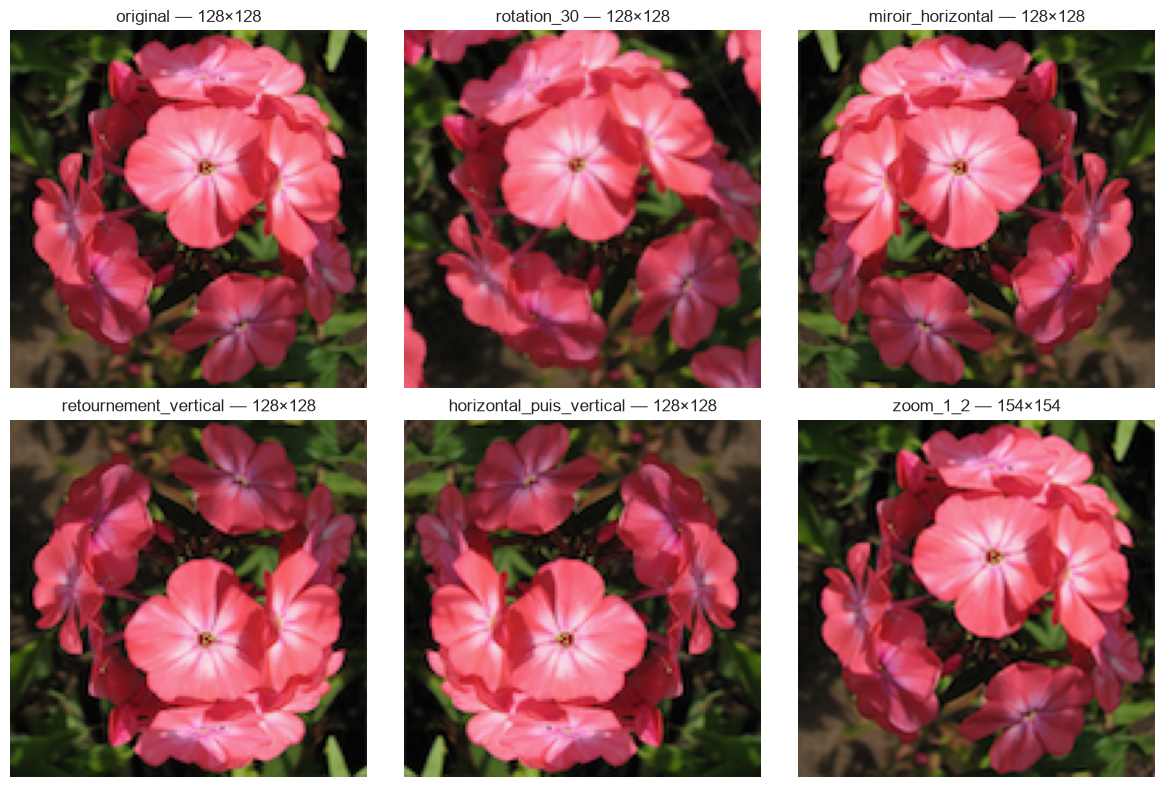

Rotation, deux retournements et zoom vérifiés.


In [2]:
from PIL import Image, ImageOps
from scipy.ndimage import rotate
image_path = DATA/'Flower Color Images Dataset'/'0001.png'
original = Image.open(image_path).convert('RGB')
def rotate_image_30_degrees(image):
    return Image.fromarray(rotate(np.asarray(image),30,axes=(1,0),reshape=False,order=1,mode='reflect').astype(np.uint8))
rotated = rotate_image_30_degrees(original)
horizontal = ImageOps.mirror(original)
vertical = ImageOps.flip(original)
both = ImageOps.flip(horizontal)
zoomed = original.resize((round(original.width*1.2),round(original.height*1.2)),Image.Resampling.LANCZOS)
variants = {'original':original,'rotation_30':rotated,'miroir_horizontal':horizontal,'retournement_vertical':vertical,'horizontal_puis_vertical':both,'zoom_1_2':zoomed}
fig,axs=plt.subplots(2,3,figsize=(12,8))
for ax,(label,image) in zip(axs.flat,variants.items()):
    ax.imshow(image);ax.set_title(f'{label} — {image.width}×{image.height}');ax.axis('off')
    image.save(RESULTS/f'flower_{label}.png')
plt.tight_layout();plt.savefig(RESULTS/'flower_transformations.png',dpi=130);plt.show()
assert rotated.size==original.size
assert zoomed.size==(round(original.width*1.2),round(original.height*1.2))
assert np.array_equal(np.asarray(horizontal),np.asarray(original)[:,::-1,:])
assert np.array_equal(np.asarray(vertical),np.asarray(original)[::-1,:,:])
assert np.array_equal(np.asarray(both),np.asarray(original)[::-1,::-1,:])
assert not np.array_equal(np.asarray(rotated),np.asarray(original))
print('Rotation, deux retournements et zoom vérifiés.')

La rotation conserve la taille (`reshape=False`) et peut couper les coins ; le mode reflect remplit les bords. Le zoom demandé agrandit le nombre de pixels de 20 % environ (arrondi au pixel entier), sans créer de nouveau détail réel. Un retournement horizontal puis vertical équivaut à une rotation de 180°. Les trois vues permettent de distinguer les opérations. Ces transformations servent à enrichir les apparences d'un jeu d'entraînement, mais ne garantissent pas à elles seules une meilleure généralisation.